In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pyart
import re

# --------------------------------------------------
# SETTINGS
# --------------------------------------------------

base_dir = Path(
    "/Volumes/Rain/LaCie/projDir/data/mdv/precip/single"
    # "/Users/matthewwright/Downloads/single_precip_sample"
    # "/Volumes/Rain/LaCie/projDir/data/mdv/radarCart/ops"
)

VAR = "rate"

date_re = re.compile(r"^\d{8}$")
file_re = re.compile(r"^\d{6}\.mdv$")

# None = process all available days
# Or specify dates, e.g. {"20190206", "20190227"}
RETRY_DAYS = None

# --------------------------------------------------
# FIND ORIGINAL MDV FILES
# --------------------------------------------------

day_dirs = sorted(
    d for d in base_dir.iterdir()
    if d.is_dir()
    and date_re.match(d.name)
    and (RETRY_DAYS is None or d.name in RETRY_DAYS)
)

files = sorted(
    f
    for d in day_dirs
    for f in d.iterdir()
    if f.is_file()
    and not f.name.startswith("._")
    and file_re.match(f.name)
)

files = files[::100]

print(f"Found {len(day_dirs)} daily directories")
print(f"Found {len(files)} MDV files")

# --------------------------------------------------
# READ MDV RAINFALL
# --------------------------------------------------

rain_values = []

total_pixels = 0
total_valid = 0
total_masked = 0
total_zero = 0
total_positive = 0
total_negative = 0

bad_files = []

for i, f in enumerate(files):

    try:
        radar = pyart.io.read_grid_mdv(
            f,
            file_field_names=True
        )

        raw = np.ma.asarray(
            radar.fields[VAR]["data"][0]
        )

        total_pixels += raw.size

        # Count masked pixels separately
        mask = np.ma.getmaskarray(raw)
        total_masked += np.sum(mask)

        # Extract unmasked, finite values
        values = raw.compressed()
        valid = values[np.isfinite(values)]

        total_valid += valid.size
        total_zero += np.sum(valid == 0)
        total_positive += np.sum(valid > 0)
        total_negative += np.sum(valid < 0)

        positive = valid[valid > 0]

        if positive.size:
            rain_values.append(positive)

    except Exception as e:
        bad_files.append((str(f), str(e)))
        print(f"BAD FILE: {f.name}: {e}")

    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1}/{len(files)} files")

# --------------------------------------------------
# COMBINE POSITIVE RAINFALL VALUES
# --------------------------------------------------

rain_values = (
    np.concatenate(rain_values)
    if rain_values
    else np.array([])
)

# --------------------------------------------------
# STATISTICS
# --------------------------------------------------

print("\nORIGINAL MDV RAINFALL STATISTICS")
print("--------------------------------------")
print(f"Total pixels:     {total_pixels:,}")
print(f"Valid pixels:     {total_valid:,}")
print(f"Masked pixels:    {total_masked:,}")
print(f"Zero pixels:      {total_zero:,}")
print(f"Positive pixels:  {total_positive:,}")
print(f"Negative pixels:  {total_negative:,}")
print(f"Bad files:        {len(bad_files):,}")

if total_valid:
    print(
        f"Fraction positive among valid: "
        f"{100 * total_positive / total_valid:.3f}%"
    )

if total_pixels:
    print(
        f"Fraction masked: "
        f"{100 * total_masked / total_pixels:.3f}%"
    )

if rain_values.size:

    print("\nPOSITIVE RAINFALL STATISTICS")
    print("--------------------------------------")
    print(f"Minimum positive: {rain_values.min():.6f}")
    print(f"Mean positive:    {rain_values.mean():.6f}")
    print(f"Median positive:  {np.median(rain_values):.6f}")
    print(f"95th percentile:  {np.percentile(rain_values, 95):.6f}")
    print(f"99th percentile:  {np.percentile(rain_values, 99):.6f}")
    print(f"Maximum:          {rain_values.max():.6f}")

# --------------------------------------------------
# HISTOGRAMS
# --------------------------------------------------

if rain_values.size:

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Linear histogram
    axes[0].hist(
        rain_values,
        bins=100,
        color="steelblue",
        edgecolor="none"
    )

    axes[0].set_xlabel("Rainfall rate (mm/h)")
    axes[0].set_ylabel("Pixel count")
    axes[0].set_title("Original MDV rainfall — linear scale")

    # Logarithmic histogram
    min_rain = rain_values.min()
    max_rain = rain_values.max()

    if min_rain < max_rain:
        log_bins = np.logspace(
            np.log10(min_rain),
            np.log10(max_rain),
            100
        )
    else:
        log_bins = np.array([
            min_rain * 0.9,
            max_rain * 1.1
        ])

    axes[1].hist(
        rain_values,
        bins=log_bins,
        color="steelblue",
        edgecolor="none"
    )

    axes[1].set_xscale("log")
    axes[1].set_yscale("log")
    axes[1].set_xlabel("Rainfall rate (mm/h)")
    axes[1].set_ylabel("Pixel count")
    axes[1].set_title("Original MDV rainfall — log scale")

    plt.tight_layout()
    plt.show()

else:
    print("\nNo positive rainfall values found.")

Found 117 daily directories
Found 260 MDV files
BAD FILE: 001757.mdv: 'RATE_HYBRID'
BAD FILE: 214027.mdv: 'RATE_HYBRID'


KeyboardInterrupt: 

In [ ]:

from pathlib import Path
from pprint import pprint
from pyart.io.mdv_common import MdvFile

# ============================================================
# 1. MDV FILE PATH
# ============================================================

MDV_FILE = Path(
    "/Volumes/Rain/LaCie/projDir/data/mdv/radarPolar/derived/sur/20190206/070402.mdv"
)

# ============================================================
# 2. READ MDV FILE
# ============================================================

mdv = MdvFile(str(MDV_FILE))

# ============================================================
# 3. MASTER HEADER
# ============================================================

print("\n" + "=" * 70)
print("MASTER HEADER")
print("=" * 70)

pprint(mdv.master_header, sort_dicts=False)

# ============================================================
# 4. FIND RATE_HYBRID FIELD
# ============================================================

target_field = "RATE_HYBRID"

hybrid_index = None
hybrid_header = None

for i, header in enumerate(mdv.field_headers):

    if header.get("field_name", "").strip() == target_field:
        hybrid_index = i
        hybrid_header = header
        break

if hybrid_header is None:
    raise ValueError(
        f"Field {target_field} not found in MDV file."
    )

# ============================================================
# 5. PRINT FULL RATE_HYBRID FIELD HEADER
# ============================================================

print("\n" + "=" * 70)
print("FULL RATE_HYBRID FIELD HEADER")
print("=" * 70)

print(f"\nField index: {hybrid_index}\n")

for key, value in hybrid_header.items():
    print(f"{key}: {value}")

# ============================================================
# 6. PRINT IMPORTANT GRID INFORMATION
# ============================================================

print("\n" + "=" * 70)
print("RATE_HYBRID GRID INFORMATION")
print("=" * 70)

grid_parameters = [
    "nx",
    "ny",
    "nz",
    "proj_type",
    "proj_origin_lat",
    "proj_origin_lon",
    "proj_rotation",
    "grid_dx",
    "grid_dy",
    "grid_dz",
    "grid_minx",
    "grid_miny",
    "grid_minz",
    "native_vlevel_type",
    "vlevel_type",
    "encoding_type",
    "compression_type",
    "scaling_type",
    "scale",
    "bias",
    "bad_data_value",
    "missing_data_value",
]

for parameter in grid_parameters:
    print(
        f"{parameter}: "
        f"{hybrid_header.get(parameter, 'Not available')}"
    )

# ============================================================
# 7. VERTICAL LEVEL HEADER
# ============================================================

print("\n" + "=" * 70)
print("RATE_HYBRID VERTICAL LEVEL HEADER")
print("=" * 70)

if hasattr(mdv, "vlevel_headers"):

    if hybrid_index < len(mdv.vlevel_headers):
        pprint(
            mdv.vlevel_headers[hybrid_index],
            sort_dicts=False
        )
    else:
        print("Vertical header index not available.")

else:
    print("No vertical headers exposed by MdvFile.")

# ============================================================
# 8. RADAR LOCATION
# ============================================================

print("\n" + "=" * 70)
print("RADAR LOCATION")
print("=" * 70)

for key in ["sensor_lat", "sensor_lon", "sensor_alt"]:
    print(f"{key}: {mdv.master_header.get(key)}")

print("\nExtraction completed successfully.")



## You are using the Python ARM Radar Toolkit (Py-ART), an open source
## library for working with weather radar data. Py-ART is partly supported
## by the U.S. Department of Energy Office of Science as part of
## the Atmospheric Radiation Measurement (ARM) User Facility.
##
## If you use this software to prepare a publication, please cite:
##
##     JJ Helmus and SM Collis, JORS 2016, doi: 10.5334/jors.119



FileNotFoundError: [Errno 2] No such file or directory: '/Volumes/Rain/LiCie/projDir/data/mdv/radarPolar/derived/sur/20190206/070402.mdv'

Found 25,272 MDV files
Processed 100/25,272 files
Processed 200/25,272 files
Processed 300/25,272 files
Processed 400/25,272 files
Processed 500/25,272 files
Processed 600/25,272 files
Processed 700/25,272 files
Processed 800/25,272 files
Processed 900/25,272 files
Processed 1,000/25,272 files
Processed 1,100/25,272 files
Processed 1,200/25,272 files
Processed 1,300/25,272 files
Processed 1,400/25,272 files
Processed 1,500/25,272 files
Processed 1,600/25,272 files
Processed 1,700/25,272 files
Processed 1,800/25,272 files
Processed 1,900/25,272 files
Processed 2,000/25,272 files
Processed 2,100/25,272 files
Processed 2,200/25,272 files
BAD FILE: /Volumes/Rain/LiCie/projDir/data/mdv/radarPolar/derived/sur/20181128/143336.mdv: error: unpack requires a buffer of 1024 bytes
Processed 2,300/25,272 files
Processed 2,400/25,272 files
BAD FILE: /Volumes/Rain/LiCie/projDir/data/mdv/radarPolar/derived/sur/20181129/082335.mdv: error: unpack requires a buffer of 1024 bytes
Processed 2,500/25,272 fi

,files,files_with_positive,total_pixels,valid_pixels,masked_%,zero_%_of_valid,positive_%_of_valid,positive_pixels,negative_pixels,min,max,mean
field,,,,,,,,,,,,
RATE_ZH,25269,25269,103350458064,4248387303,0.0,0.0,100.0,4248387303,0,0.10,114.659996,1.945499
RATE_Z_ZDR,25269,25269,103350458064,3099050661,0.0,0.0,100.0,3099050661,0,0.10,250.000000,2.977691
RATE_KDP,25269,24166,103350458064,1102050726,0.0,0.0,100.0,1102050726,0,1.33,250.000000,18.715732
RATE_KDP_ZDR,25269,23081,103350458064,228999297,0.0,0.0,100.0,228999297,0,0.10,250.000000,27.907069
RATE_HYBRID,25269,25269,103350458064,3044230325,0.0,0.0,100.0,3044230325,0,0.10,250.000000,2.650509
RATE_PID,25269,25267,103350458064,2789117425,0.0,0.0,100.0,2789117425,0,0.08,250.000000,2.848570
PID,25269,25268,103350458064,7996055096,0.0,0.0,100.0,7996055096,0,2.00,17.000000,13.482576



Bad files: 3


,file,error_type,message
0,/Volumes/Rain/LiCie/projDir/data/mdv/radarPola...,error,unpack requires a buffer of 1024 bytes
1,/Volumes/Rain/LiCie/projDir/data/mdv/radarPola...,error,unpack requires a buffer of 1024 bytes
2,/Volumes/Rain/LiCie/projDir/data/mdv/radarPola...,error,unpack requires a buffer of 1024 bytes


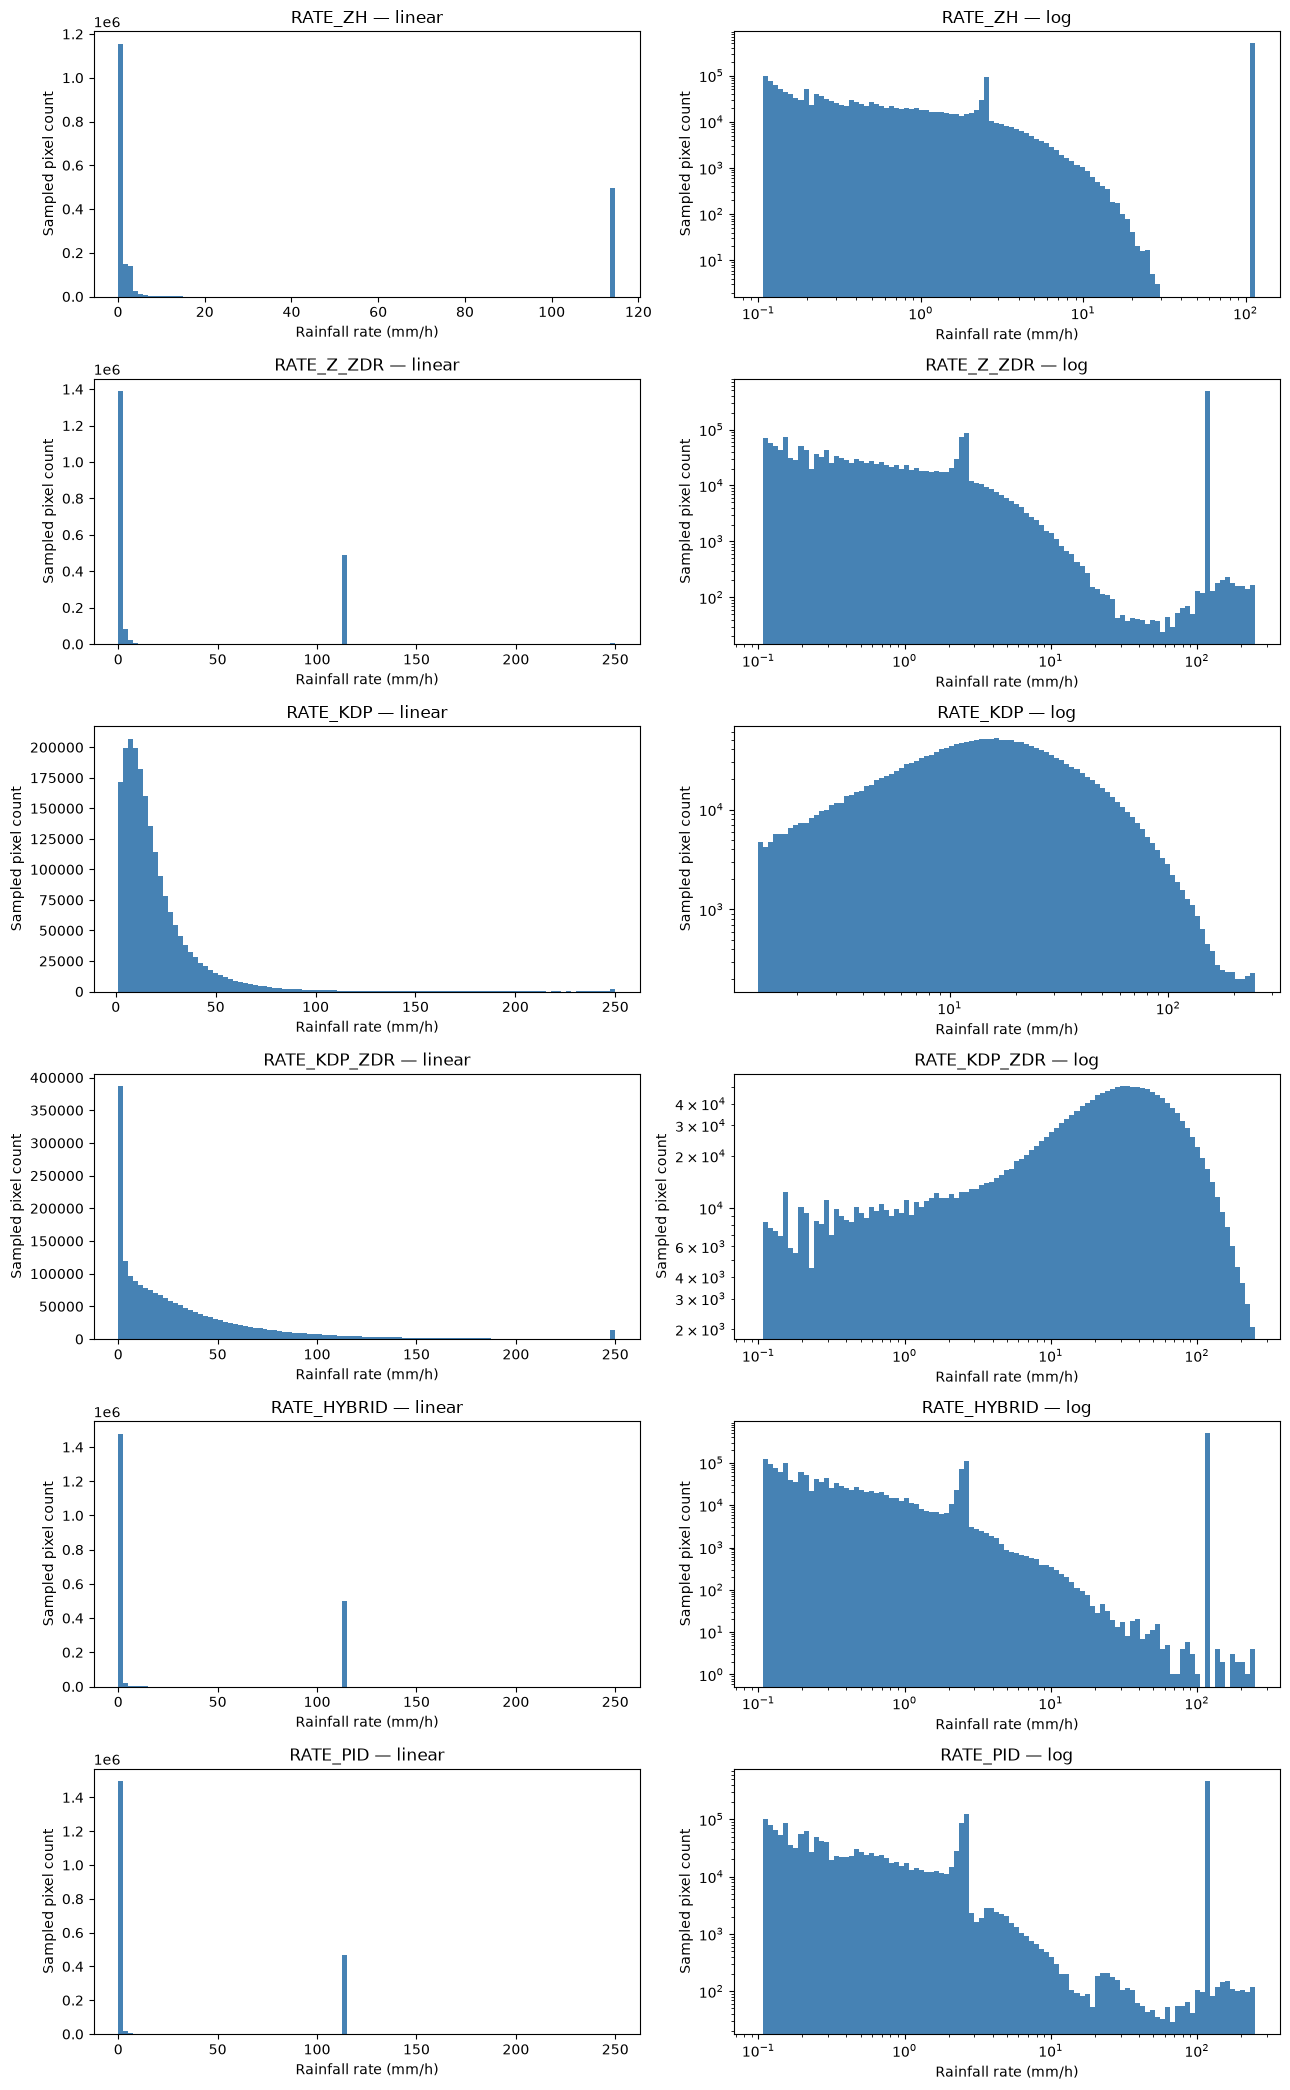

In [ ]:

from pathlib import Path
from collections import defaultdict
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyart.io.mdv_common import MdvFile

# --------------------------------------------------
# SETTINGS
# --------------------------------------------------

base_dir = Path(
    # "/Volumes/Rain/LiCie/projDir/data/mdv/radarPolar/derived/sur"
)

# None = all days
# Or e.g. {"20190206", "20190227"}
RETRY_DAYS = None

# None = all files
MAX_FILES = None

FIELDS = [
    "RATE_ZH",
    "RATE_Z_ZDR",
    "RATE_KDP",
    "RATE_KDP_ZDR",
    "RATE_HYBRID",
    "RATE_PID",
    "PID",
]

# Store positive rainfall values for histograms.
# Set a limit to avoid excessive memory use.
MAX_HIST_VALUES_PER_FIELD = 2_000_000

date_re = re.compile(r"^\d{8}$")
file_re = re.compile(r"^\d{6}\.mdv$")

# --------------------------------------------------
# FIND MDV FILES
# --------------------------------------------------

# Search recursively because polar MDV products may
# have additional directory levels.

files = sorted(
    f for f in base_dir.rglob("*.mdv")
    if f.is_file()
    and not f.name.startswith("._")
    and file_re.fullmatch(f.name)
    and (
        RETRY_DAYS is None
        or any(
            part in RETRY_DAYS
            for part in f.parts
            if date_re.fullmatch(part)
        )
    )
)

if MAX_FILES is not None:
    files = files[:MAX_FILES]

print(f"Found {len(files):,} MDV files")

# --------------------------------------------------
# INITIALISE STATISTICS
# --------------------------------------------------

stats = defaultdict(lambda: {
    "files": 0,
    "files_with_positive": 0,
    "total": 0,
    "masked": 0,
    "nonfinite_unmasked": 0,
    "valid": 0,
    "zero": 0,
    "positive": 0,
    "negative": 0,
    "sum": 0.0,
    "min": np.inf,
    "max": -np.inf,
})

hist_values = defaultdict(list)
hist_counts = defaultdict(int)

bad_files = []

# --------------------------------------------------
# READ FILES
# --------------------------------------------------

for i, f in enumerate(files):

    try:
        mdv = MdvFile(str(f))

        # Read all field data using the low-level reader.
        # MdvFile.read_all_fields() populates fields
        # with decoded numerical arrays.
        mdv.read_all_fields()

        for field_index, header in enumerate(mdv.field_headers):

            name = header["field_name"].strip()

            if name not in FIELDS:
                continue

            raw = np.ma.asarray(
                mdv.fields_data[field_index]
            )

            mask = np.ma.getmaskarray(raw)

            values = raw.compressed()
            finite = values[np.isfinite(values)]

            s = stats[name]

            s["files"] += 1
            s["total"] += raw.size
            s["masked"] += int(mask.sum())
            s["nonfinite_unmasked"] += int(
                values.size - finite.size
            )
            s["valid"] += finite.size

            if finite.size == 0:
                continue

            zero = finite == 0
            positive = finite > 0
            negative = finite < 0

            n_positive = int(positive.sum())

            s["zero"] += int(zero.sum())
            s["positive"] += n_positive
            s["negative"] += int(negative.sum())

            s["sum"] += float(finite.sum())
            s["min"] = min(s["min"], float(finite.min()))
            s["max"] = max(s["max"], float(finite.max()))

            if n_positive:
                s["files_with_positive"] += 1

            # Collect positive values for histograms
            # (rainfall fields only).
            if name.startswith("RATE_") and n_positive:

                remaining = (
                    MAX_HIST_VALUES_PER_FIELD
                    - hist_counts[name]
                )

                if remaining > 0:

                    positive_values = finite[positive]

                    # Sample evenly if the file contains
                    # more values than the remaining limit.
                    if positive_values.size > remaining:
                        indices = np.linspace(
                            0,
                            positive_values.size - 1,
                            remaining,
                            dtype=int,
                        )
                        positive_values = positive_values[indices]

                    hist_values[name].append(
                        positive_values.astype(np.float32)
                    )

                    hist_counts[name] += positive_values.size

    except Exception as e:
        bad_files.append((str(f), type(e).__name__, str(e)))
        print(f"BAD FILE: {f}: {type(e).__name__}: {e}")

    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1:,}/{len(files):,} files")

# --------------------------------------------------
# SUMMARY TABLE
# --------------------------------------------------

rows = []

for name in FIELDS:

    s = stats[name]

    rows.append({
        "field": name,
        "files": s["files"],
        "files_with_positive": s["files_with_positive"],
        "total_pixels": s["total"],
        "valid_pixels": s["valid"],
        "masked_%": (
            100 * s["masked"] / s["total"]
            if s["total"] else np.nan
        ),
        "zero_%_of_valid": (
            100 * s["zero"] / s["valid"]
            if s["valid"] else np.nan
        ),
        "positive_%_of_valid": (
            100 * s["positive"] / s["valid"]
            if s["valid"] else np.nan
        ),
        "positive_pixels": s["positive"],
        "negative_pixels": s["negative"],
        "min": (
            s["min"] if s["valid"] else np.nan
        ),
        "max": (
            s["max"] if s["valid"] else np.nan
        ),
        "mean": (
            s["sum"] / s["valid"]
            if s["valid"] else np.nan
        ),
    })

summary = pd.DataFrame(rows).set_index("field")

print("\n" + "=" * 75)
print("MDV FIELD STATISTICS")
print("=" * 75)

display(summary)

print(f"\nBad files: {len(bad_files):,}")

if bad_files:
    display(pd.DataFrame(
        bad_files,
        columns=["file", "error_type", "message"]
    ).head(20))

# --------------------------------------------------
# RAINFALL HISTOGRAMS
# --------------------------------------------------

rain_fields = [f for f in FIELDS if f.startswith("RATE_")]

fig, axes = plt.subplots(
    len(rain_fields),
    2,
    figsize=(13, 3.5 * len(rain_fields)),
)

for row, name in enumerate(rain_fields):

    if not hist_values[name]:
        axes[row, 0].text(
            0.5, 0.5, "No positive rainfall",
            ha="center", va="center",
            transform=axes[row, 0].transAxes,
        )
        axes[row, 1].text(
            0.5, 0.5, "No positive rainfall",
            ha="center", va="center",
            transform=axes[row, 1].transAxes,
        )
        axes[row, 0].set_title(name)
        axes[row, 1].set_title(name)
        continue

    values = np.concatenate(hist_values[name])

    axes[row, 0].hist(
        values,
        bins=100,
        color="steelblue",
    )
    axes[row, 0].set_title(f"{name} — linear")
    axes[row, 0].set_xlabel("Rainfall rate (mm/h)")
    axes[row, 0].set_ylabel("Sampled pixel count")

    vmin = values.min()
    vmax = values.max()

    if vmin < vmax:
        bins = np.logspace(
            np.log10(vmin),
            np.log10(vmax),
            100,
        )
    else:
        bins = np.array([vmin * 0.9, vmax * 1.1])

    axes[row, 1].hist(
        values,
        bins=bins,
        color="steelblue",
    )
    axes[row, 1].set_xscale("log")
    axes[row, 1].set_yscale("log")
    axes[row, 1].set_title(f"{name} — log")
    axes[row, 1].set_xlabel("Rainfall rate (mm/h)")
    axes[row, 1].set_ylabel("Sampled pixel count")

plt.tight_layout()
plt.show()
